In [ ]:
# Dependencies: numpy, pandas, matplotlib.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({
    "font.size": 15,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.0,
    "ytick.major.width": 0.0,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

BASE_DIR = "/data/traid"
INPUT_CSV = f"{BASE_DIR}/twohop_comp_effect.csv"

PERIOD_ORDER = ["g = 1 (2020)", "g = 2 (2021)", "g = 3 (2022)", "Ever (g >= 1)"]
PAIR_ORDER = ["Cross-industry", "Within-industry"]
COLORS = {
    "Cross-industry": "#72B0AB",
    "Within-industry": "#FE9179",
}


In [2]:
df = pd.read_csv(INPUT_CSV)

df_plot = df.loc[df["measure"].eq("Interaction strength with shared neighbors")].copy()
df_plot["period"] = pd.Categorical(df_plot["period"], categories=PERIOD_ORDER, ordered=True)
df_plot["pair_type"] = pd.Categorical(df_plot["pair_type"], categories=PAIR_ORDER, ordered=True)
df_plot = df_plot.sort_values(["period", "pair_type"])
df_plot["label"] = df_plot["estimate"].map(lambda x: f"{x:.3f}")


Figure 4b

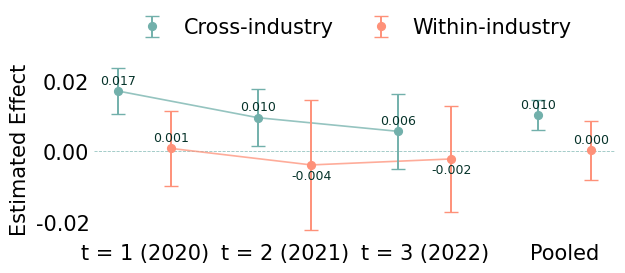

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3), dpi=100)

x_base = np.arange(len(PERIOD_ORDER))
offsets = {
    "Cross-industry": -0.19,
    "Within-industry": 0.19,
}

ax.axhline(
    0,
    linestyle="--",
    color="#72B0AB",
    linewidth=0.6,
    alpha=0.75,
    zorder=0,
)

for pair_type in PAIR_ORDER:
    sub = (
        df_plot[df_plot["pair_type"].eq(pair_type)]
        .set_index("period")
        .loc[PERIOD_ORDER]
        .reset_index()
    )
    x = x_base + offsets[pair_type]
    y = sub["estimate"].to_numpy()
    yerr = np.vstack([
        y - sub["conf.low"].to_numpy(),
        sub["conf.high"].to_numpy() - y,
    ])

    trend_mask = sub["period"].isin(PERIOD_ORDER[:3]).to_numpy()
    ax.plot(
        x[trend_mask],
        y[trend_mask],
        color=COLORS[pair_type],
        linewidth=1.2,
        alpha=0.75,
        zorder=1,
    )

    ax.errorbar(
        x,
        y,
        yerr=yerr,
        fmt="o",
        markersize=5.6,
        markerfacecolor=COLORS[pair_type],
        markeredgecolor=COLORS[pair_type],
        ecolor=COLORS[pair_type],
        elinewidth=1.4,
        capsize=5,
        capthick=1,
        label=pair_type,
        zorder=2,
    )

    for xi, yi, label in zip(x, y, sub["label"]):
        va = "bottom" if yi >= 0 else "top"
        dy = 0.0012 if yi >= 0 else -0.0012
        ax.text(
            xi,
            yi + dy,
            label,
            ha="center",
            va=va,
            fontsize=9,
            color="#053229",
        )

ax.set_xticks(x_base)
ax.set_xticklabels(["t = 1 (2020)", "t = 2 (2021)", "t = 3 (2022)", "Pooled"])
ax.set_xlabel("")
ax.set_ylabel("Estimated Effect")

ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="both", length=0, colors="black")

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    handlelength=1.4,
    columnspacing=1.6,
)

fig.tight_layout()
plt.show()


Figure 4c

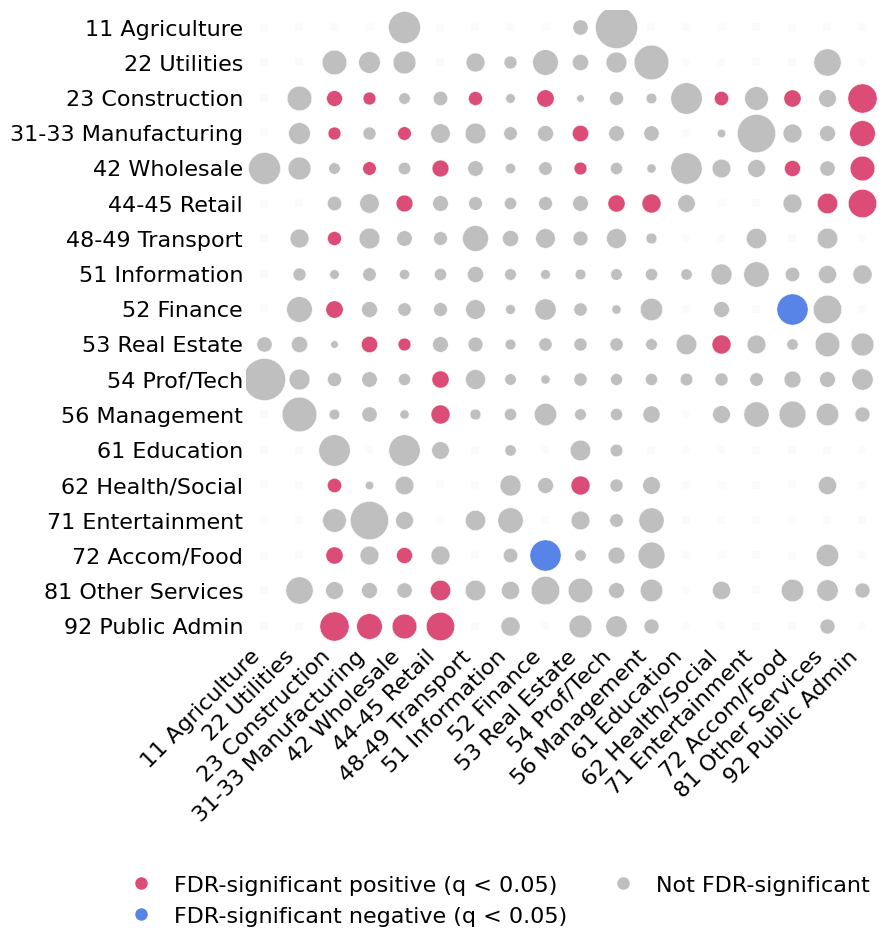

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

BASE_DIR = "/home/chen/Notebook/main/traid"
STRENGTH_CSV = f"{BASE_DIR}/industry_coef_strength.csv"
FDR_ALPHA = 0.05

naics_order = [
    "11", "22", "23", "31-33", "42", "44-45", "48-49",
    "51", "52", "53", "54", "56", "61", "62", "71", "72", "81", "92"
]

naics_labels = {
    "11": "11 Agriculture",
    "21": "21 Mining",
    "22": "22 Utilities",
    "23": "23 Construction",
    "31-33": "31-33 Manufacturing",
    "42": "42 Wholesale",
    "44-45": "44-45 Retail",
    "48-49": "48-49 Transport",
    "51": "51 Information",
    "52": "52 Finance",
    "53": "53 Real Estate",
    "54": "54 Prof/Tech",
    "56": "56 Management",
    "61": "61 Education",
    "62": "62 Health/Social",
    "71": "71 Entertainment",
    "72": "72 Accom/Food",
    "81": "81 Other Services",
    "92": "92 Public Admin",
}

def prepare_coef(df):
    out = df.copy()
    parts = out["pair_type_naics"].astype(str).str.split("_", n=1, expand=True)
    out["ind_i"] = parts[0]
    out["ind_j"] = parts[1]

    p_values = pd.to_numeric(out["p.value"], errors="raise").to_numpy(dtype=float)
    sort_idx = np.argsort(p_values, kind="stable")
    ranked_p = p_values[sort_idx]
    adjusted_sorted = ranked_p * len(ranked_p) / np.arange(1, len(ranked_p) + 1)
    adjusted_sorted = np.minimum.accumulate(adjusted_sorted[::-1])[::-1]
    adjusted = np.empty_like(p_values)
    adjusted[sort_idx] = np.clip(adjusted_sorted, 0, 1)
    out["p_value_bh"] = adjusted
    out["sig"] = out["p_value_bh"] < FDR_ALPHA
    out["sig_pos"] = out["sig"] & (out["estimate"] > 0)
    out["sig_neg"] = out["sig"] & (out["estimate"] < 0)
    return out

def symmetrize(df):
    mirrored = df.copy()
    mirrored[["ind_i", "ind_j"]] = mirrored[["ind_j", "ind_i"]]
    return pd.concat([df, mirrored[df["ind_i"] != df["ind_j"]]], ignore_index=True)

def sig_color(beta, is_sig):
    if not is_sig:
        return "#bfbfbf"
    return "#DB4C77" if beta > 0 else "#5784E6"

def dot_size(beta, max_beta):
    magnitude = abs(beta) / max_beta
    return 18 + 900 * np.sqrt(magnitude)

def setup_matrix_axes(ax, title, order=naics_order):
    n_dim = len(order)
    axis_labels = [naics_labels[x] for x in order]

    ax.set_xticks(range(n_dim))
    ax.set_yticks(range(n_dim))
    ax.set_xticklabels(axis_labels, rotation=45, ha="right", fontsize=16)
    ax.set_yticklabels(axis_labels, fontsize=16)

    ax.set_xlim(-0.5, n_dim - 0.5)
    ax.set_ylim(n_dim - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.tick_params(length=0, pad=2)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.figure.patch.set_facecolor("white")
    ax.set_facecolor("white")

def draw_dot_matrix(df, title, order=naics_order):
    plot = df[df["ind_i"].isin(order) & df["ind_j"].isin(order)].copy()
    x_map = {v: i for i, v in enumerate(order)}
    y_map = {v: i for i, v in enumerate(order)}
    plot["x"] = plot["ind_j"].map(x_map)
    plot["y"] = plot["ind_i"].map(y_map)

    max_beta = plot["estimate"].abs().max()
    fig, ax = plt.subplots(dpi=100, figsize=(12, 9.5))

    for i in range(len(order)):
        for j in range(len(order)):
            ax.scatter(j, i, s=38, color="#fbfbfb", marker="s", linewidths=0, zorder=1)

    for _, row in plot.iterrows():
        beta = row["estimate"]
        ax.scatter(
            row["x"],
            row["y"],
            s=dot_size(beta, max_beta),
            c=sig_color(beta, row["sig"]),
            alpha=1.0,
            marker="o",
            edgecolors="#ffffff",
            linewidths=0.35,
            zorder=3,
        )

    setup_matrix_axes(ax, title, order)

    color_handles = [
        plt.Line2D([0], [0], marker="o", color="w", label="FDR-significant positive (q < 0.05)",
                   markerfacecolor="#DB4C77", markeredgecolor="#ffffff", markersize=10),
        plt.Line2D([0], [0], marker="o", color="w", label="FDR-significant negative (q < 0.05)",
                   markerfacecolor="#5784E6", markeredgecolor="#ffffff", markersize=10),
        plt.Line2D([0], [0], marker="o", color="w", label="Not FDR-significant",
                   markerfacecolor="#bfbfbf", markeredgecolor="#ffffff", markersize=10),
    ]
    fig.legend(
        handles=color_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=2,
        frameon=False,
        fontsize=16,
        handletextpad=0.5,
        columnspacing=1.5,
        borderaxespad=0,
    )

    fig.tight_layout(rect=(0, 0.11, 1, 1))
    plt.show()
    plt.close(fig)

strength_m = symmetrize(prepare_coef(pd.read_csv(STRENGTH_CSV)))
draw_dot_matrix(
    strength_m,
    "",
)
